In [9]:
# データと正解を出す総当たり探索
import heapq
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
centers = np.array([[0, 0], [6, 1], [2, 6]])

# 3つの塊を持つ2次元データ（210点）
X = np.vstack([c + rng.normal(scale=1.0, size=(70, 2)) for c in centers])
q = np.array([3.0, 2.5]) # クエリ点

def brute_force_knn(X, q, k):
    d = np.linalg.norm(X - q, axis=1) # 全点との距離を計算（N回）
    idx = np.argsort(d)[:k]
    return idx, d[idx]

In [10]:
# ノードの定義
class Node:
    def __init__(self, idx, center, radius, depth):
        self.idx = idx       # このノードが含む点の番号（Xの行番号）
        self.center = center # 球の中心
        self.radius = radius # 球の半径
        self.depth = depth   # 根からの深さ
        self.left = None
        self.right = None

    @property
    def is_leaf(self):
        return self.left is None

In [11]:
# 構築
def build(X, idx=None, depth=0, leaf_size=10):
    if idx is None:
        idx = np.arange(len(X))
    pts = X[idx]
    center = pts.mean(axis=0)
    radius = np.linalg.norm(pts - center, axis=1).max()
    node = Node(idx, center, radius, depth)
    if len(idx) <= leaf_size:
        return node
    dim = np.argmax(pts.max(axis=0) - pts.min(axis=0))
    order = np.argsort(pts[:, dim])
    half = len(idx) // 2
    node.left = build(X, idx[order[:half]], depth + 1, leaf_size)
    node.right = build(X, idx[order[half:]], depth + 1, leaf_size)
    return node

root = build(X)

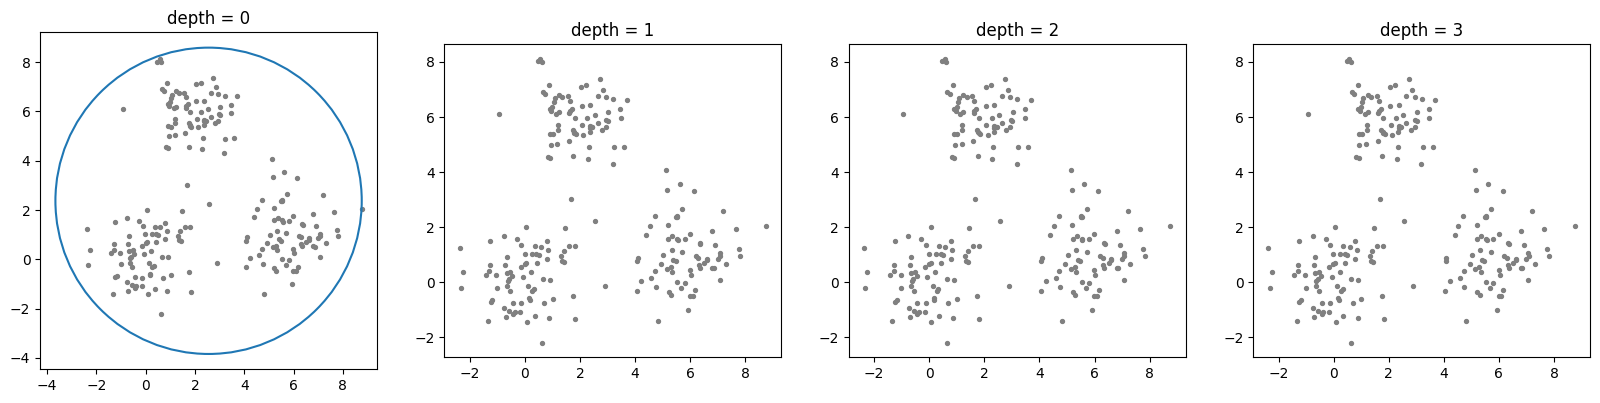

In [12]:
# 構築結果の描画
def draw_tree(X, root, max_depth, ax):
    ax.scatter(X[:, 0], X[:, 1], s=8, c="gray")
    cmap = plt.get_cmap("tab10")
    stack = [root]
    while stack:
        n = stack.pop()
        # 指定の深さのノード、またはそれより浅い位置で葉になったノードを描画
        if n.depth == max_depth or (n.is_leaf and n.depth < max_depth):
            ax.add_patch(plt.Circle(n.center, n.radius, fill=False, color=cmap(n.depth % 10), lw=1.5))
            if not n.is_leaf and n.depth < max_depth:
                stack += [n.leaf, n.right]
    ax.set_aspect("equal")
    ax.set_title(f"depth = {max_depth}")

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for d, ax in enumerate(axes):
    draw_tree(X, root, d, ax)
plt.show()

In [15]:
# k近傍探索
def knn(X, root, q, k):
    heap = []   # (-距離, 点番号) を最大k個保持
    log = {"dist_calc": 0, "visited_leaves": [], "pruned": []}

    def worst():
        # 現在のk番目の距離。k個そろうまでは無限大（枝刈りしない）
        return -heap[0][0] if len(heap) == k else np.inf

    def search(node):
        d_center = np.linalg.norm(q - node.center)
        log["dist_calc"] += 1
        lower = max(d_center - node.radius, 0.0)   # 球内の点までの距離の下限
        if lower >= worst():                        # 1. 枝刈り
            log["pruned"].append(node)
            return
        if node.is_leaf:                            # 2. 葉：全点を調べる
            log["visited_leaves"].append(node)
            for i in node.idx:
                d = np.linalg.norm(q - X[i])
                log["dist_calc"] += 1
                if len(heap) < k:
                    heapq.heappush(heap, (-d, i))
                elif d < worst():
                    heapq.heapreplace(heap, (-d, i))
            return
        # 3. 近い子を先に探索
        dl = np.linalg.norm(q - node.left.center)
        dr = np.linalg.norm(q - node.right.center)
        first, second = (node.left, node.right) if dl <= dr else (node.right, node.left)
        search(first)
        search(second)

    search(root)
    res = sorted((-nd, i) for nd, i in heap)
    return np.array([i for _, i in res]), np.array([d for d, _ in res]), log

距離計算回数: 85 / 総当たり: 210
調べた葉: 8  枝刈り: 9


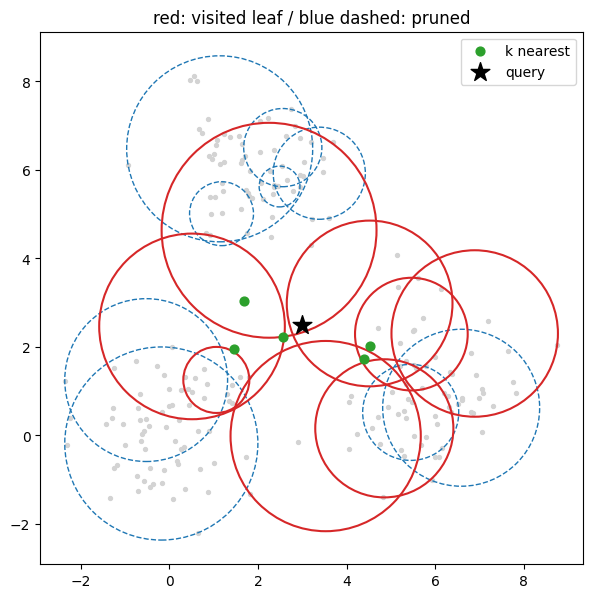

In [16]:
# 探索過程の描画
def draw_search(X, q, idx, log, ax):
    ax.scatter(X[:, 0], X[:, 1], s=8, c="lightgray")
    for n in log["pruned"]:
        ax.add_patch(plt.Circle(n.center, n.radius, fill=False,
                                color="tab:blue", ls="--", lw=1))
    for n in log["visited_leaves"]:
        ax.add_patch(plt.Circle(n.center, n.radius, fill=False,
                                color="tab:red", lw=1.5))
    ax.scatter(X[idx, 0], X[idx, 1], s=40, c="tab:green", label="k nearest")
    ax.scatter(*q, marker="*", s=200, c="black", label="query")
    ax.set_aspect("equal")
    ax.legend()
    ax.set_title("red: visited leaf / blue dashed: pruned")

k = 5
idx, dist, log = knn(X, root, q, k)
print("距離計算回数:", log["dist_calc"], "/ 総当たり:", len(X))
print("調べた葉:", len(log["visited_leaves"]), " 枝刈り:", len(log["pruned"]))

fig, ax = plt.subplots(figsize=(7, 7))
draw_search(X, q, idx, log, ax)
plt.show()

In [17]:
# 検証
from sklearn.neighbors import BallTree

bi, bd = brute_force_knn(X, q, k)
print("総当たりと一致:", np.allclose(dist, bd))

sd, si = BallTree(X, leaf_size=10).query(q.reshape(1, -1), k=k)
print("sklearnと一致:", np.allclose(sd[0], dist))

# ランダムなクエリ200個でも確認
for _ in range(200):
    qq = rng.uniform(-3, 9, size=2)
    _, ad, _ = knn(X, root, qq, k)
    _, bd2 = brute_force_knn(X, qq, k)
    assert np.allclose(ad, bd2)
print("200件すべて一致")

総当たりと一致: True
sklearnと一致: True
200件すべて一致


In [18]:
# 条件を変える実験
for dim in [2, 5, 10, 20, 50]:
    Xd = rng.normal(size=(2000, dim))
    r = build(Xd)
    calc = np.mean([knn(Xd, r, rng.normal(size=dim), 5)[2]["dist_calc"]
                    for _ in range(20)])
    print(f"dim={dim:2d}  距離計算 {calc:7.1f} 回  (総当たり比 {calc/len(Xd):.2f})")

dim= 2  距離計算   100.7 回  (総当たり比 0.05)
dim= 5  距離計算   818.8 回  (総当たり比 0.41)
dim=10  距離計算  2262.9 回  (総当たり比 1.13)
dim=20  距離計算  2511.0 回  (総当たり比 1.26)
dim=50  距離計算  2511.0 回  (総当たり比 1.26)
